
# DAML Homework 3 — Exploration Studio
## Unsupervised learning after hours: test assumptions, break K-means, and chase hidden structure

**Ungraded · Do not submit · Choose your own path · Approximately 10–120+ minutes**

This notebook is a sandbox built around the same spacecraft telemetry story as **Orbital Black Box**. It is not another assignment. Run one section, change something, make a prediction, and see whether the algorithm agrees with your intuition.

> **Best habit:** predict first, run second, explain third.



## Map of the studio

1. **Scaling changes geometry**
2. **Initialization lottery**
3. **How many clusters? Elbow versus silhouette**
4. **Break K-means on purpose**
5. **Turn the soft-membership temperature dial**
6. **PCA as a compressor**
7. **NMF as additive latent programs**
8. **Viterbi smoothing: time as evidence**
9. **Autoencoders: the nonlinear next step**
10. **Tutorial library and mini-project menu**

All code below is supplied. The learning comes from changing parameters and explaining what moved—and what did not.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA, NMF
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=4, suppress=True)
print("Exploration Studio ready.")


Exploration Studio ready.



## Mission data

The generator below creates six observed telemetry channels from three recurring latent operating modes. The hidden mode labels are used only to synthesize the data; the exploration workflow does **not** receive them.


In [2]:

FEATURE_NAMES = np.array([
    "bus_power_w",
    "wheel_vibration_g",
    "thermal_gradient_c",
    "radio_activity",
    "attitude_error_deg",
    "magnetic_noise",
])


def make_orbital_telemetry(n_steps=240, seed=17):
    rng = np.random.default_rng(seed)
    transition = np.array([
        [0.93, 0.05, 0.02],
        [0.06, 0.90, 0.04],
        [0.04, 0.08, 0.88],
    ])
    hidden_state = np.zeros(n_steps, dtype=int)
    for t in range(1, n_steps):
        hidden_state[t] = rng.choice(3, p=transition[hidden_state[t - 1]])

    latent_means = np.array([
        [-1.50, -0.60,  0.20],
        [ 1.45, -0.10, -0.45],
        [ 0.20,  1.25,  0.65],
    ])
    latent_covariances = np.array([
        [[0.32,  0.08,  0.00], [ 0.08, 0.22, 0.03], [ 0.00, 0.03, 0.16]],
        [[0.30, -0.06,  0.03], [-0.06, 0.25, 0.00], [ 0.03, 0.00, 0.22]],
        [[0.38,  0.04, -0.03], [ 0.04, 0.30, 0.05], [-0.03, 0.05, 0.24]],
    ])

    latent = np.empty((n_steps, 3))
    for t in range(n_steps):
        mean = latent_means[hidden_state[t]].copy()
        if t > 0 and hidden_state[t] != hidden_state[t - 1]:
            mean = 0.50 * latent_means[hidden_state[t - 1]] + 0.50 * latent_means[hidden_state[t]]
        latent[t] = rng.multivariate_normal(mean, latent_covariances[hidden_state[t]])

    mixing = np.array([
        [ 1.2,  0.2, -0.1],
        [ 0.1,  1.0,  0.3],
        [-0.5,  0.2,  0.8],
        [ 0.7, -0.6,  0.1],
        [ 0.2,  0.4,  1.1],
        [-0.8,  0.1,  0.4],
    ])
    observed = latent @ mixing.T + rng.normal(scale=0.16, size=(n_steps, 6))
    scales = np.array([35.0, 0.8, 18.0, 120.0, 2.5, 0.04])
    offsets = np.array([120.0, 2.0, 60.0, 400.0, 8.0, 0.2])
    return observed * scales + offsets


X_raw = make_orbital_telemetry()
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print("Raw shape:", X_raw.shape)
print("Standardized means:", X.mean(axis=0))
print("Standardized standard deviations:", X.std(axis=0))


Raw shape: (240, 6)
Standardized means: [-0.  0. -0.  0.  0.  0.]
Standardized standard deviations: [1. 1. 1. 1. 1. 1.]


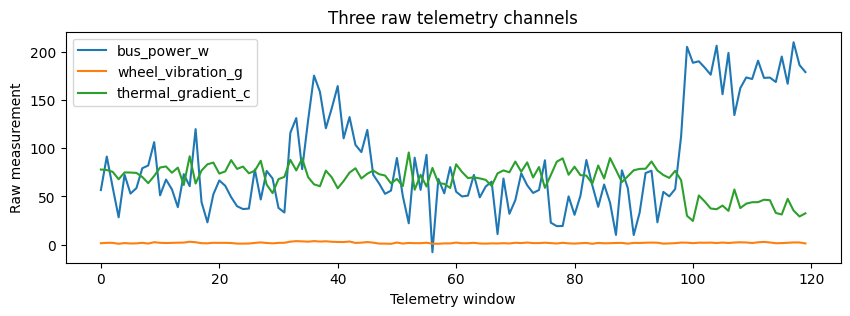

In [3]:

plt.figure(figsize=(10, 3))
for column in range(3):
    plt.plot(X_raw[:120, column], label=FEATURE_NAMES[column])
plt.xlabel("Telemetry window")
plt.ylabel("Raw measurement")
plt.title("Three raw telemetry channels")
plt.legend()
plt.show()



# 1. Scaling changes geometry

K-means uses Euclidean distance. Multiplying one feature by 100 changes the geometry even if the underlying spacecraft behavior has not changed.

**Predict first:** Will clustering raw measurements and standardized measurements produce the same partition?


Raw feature standard deviations:
  bus_power_w                 59.6198
  wheel_vibration_g            0.6078
  thermal_gradient_c          16.6975
  radio_activity             103.4077
  attitude_error_deg           1.7343
  magnetic_noise               0.0468

Agreement between raw-space and standardized-space partitions (ARI): 0.40062418672285743
Raw-space cluster sizes:          [97 90 53]
Standardized-space cluster sizes: [144  61  35]


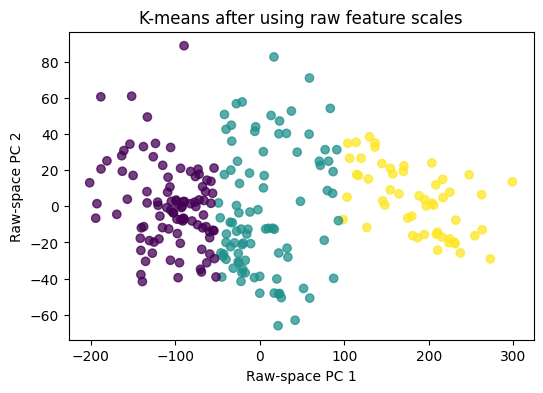

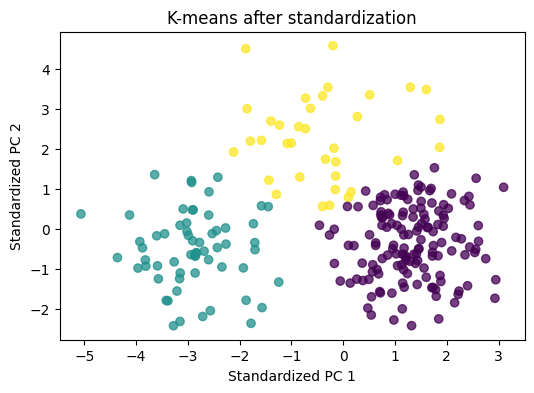

In [4]:

raw_model = KMeans(n_clusters=3, n_init=30, random_state=0).fit(X_raw)
standard_model = KMeans(n_clusters=3, n_init=30, random_state=0).fit(X)

raw_labels = raw_model.labels_
standard_labels = standard_model.labels_

print("Raw feature standard deviations:")
for name, value in zip(FEATURE_NAMES, X_raw.std(axis=0)):
    print(f"  {name:24s} {value:10.4f}")
print()
print("Agreement between raw-space and standardized-space partitions (ARI):",
      adjusted_rand_score(raw_labels, standard_labels))
print("Raw-space cluster sizes:         ", np.bincount(raw_labels, minlength=3))
print("Standardized-space cluster sizes:", np.bincount(standard_labels, minlength=3))

raw_view = PCA(n_components=2).fit_transform(X_raw)
plt.figure(figsize=(6, 4))
plt.scatter(raw_view[:, 0], raw_view[:, 1], c=raw_labels, alpha=0.75)
plt.xlabel("Raw-space PC 1")
plt.ylabel("Raw-space PC 2")
plt.title("K-means after using raw feature scales")
plt.show()

standard_view = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(6, 4))
plt.scatter(standard_view[:, 0], standard_view[:, 1], c=standard_labels, alpha=0.75)
plt.xlabel("Standardized PC 1")
plt.ylabel("Standardized PC 2")
plt.title("K-means after standardization")
plt.show()



### What to notice

- Inertia values from raw and standardized spaces are not directly comparable because the coordinate systems use different scales.
- Standardization does not guarantee a better semantic answer. It encodes the choice that one standard deviation in each feature should count similarly.
- A similarity metric is part of the model, even when it looks like “just preprocessing.”

**Try:** multiply one standardized column by 2, 5, and 20. Track when the partition begins to change.



# 2. Initialization lottery

Lloyd's K-means algorithm can settle in different local solutions. Compare single-run random initialization with K-means++.

**Predict first:** Which initialization strategy will have lower spread in final inertia?


Random initialization:   best / median / worst = 330.72982234785206 333.7663271395228 401.32459861346973
K-means++ initialization: best / median / worst = 330.72982234785206 333.33060640911543 342.3001495902175


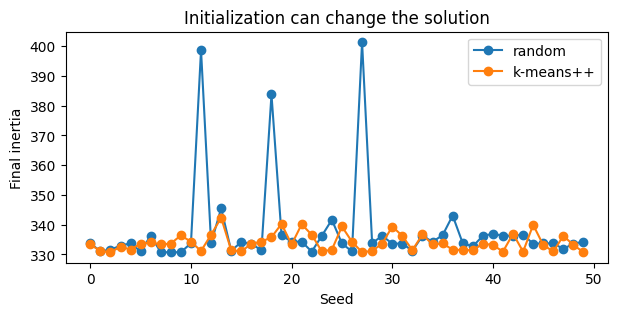

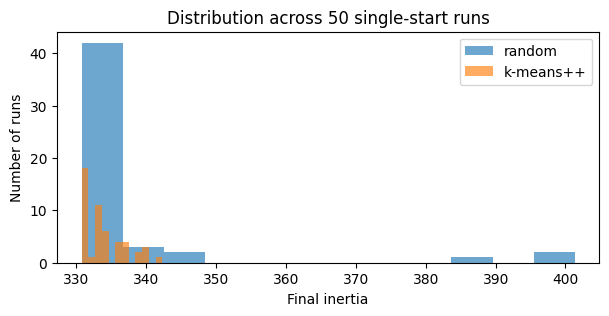

In [5]:

seeds = np.arange(50)
random_inertias = []
plus_inertias = []

for seed in seeds:
    random_inertias.append(
        KMeans(n_clusters=5, init="random", n_init=1, random_state=int(seed)).fit(X).inertia_
    )
    plus_inertias.append(
        KMeans(n_clusters=5, init="k-means++", n_init=1, random_state=int(seed)).fit(X).inertia_
    )

random_inertias = np.array(random_inertias)
plus_inertias = np.array(plus_inertias)

print("Random initialization:   best / median / worst =",
      random_inertias.min(), np.median(random_inertias), random_inertias.max())
print("K-means++ initialization: best / median / worst =",
      plus_inertias.min(), np.median(plus_inertias), plus_inertias.max())

plt.figure(figsize=(7, 3))
plt.plot(seeds, random_inertias, marker="o", label="random")
plt.plot(seeds, plus_inertias, marker="o", label="k-means++")
plt.xlabel("Seed")
plt.ylabel("Final inertia")
plt.title("Initialization can change the solution")
plt.legend()
plt.show()

plt.figure(figsize=(7, 3))
plt.hist(random_inertias, bins=12, alpha=0.65, label="random")
plt.hist(plus_inertias, bins=12, alpha=0.65, label="k-means++")
plt.xlabel("Final inertia")
plt.ylabel("Number of runs")
plt.title("Distribution across 50 single-start runs")
plt.legend()
plt.show()



### What to notice

- K-means++ improves the starting geometry; it does not make the objective convex.
- `n_init` is not decorative. Multiple starts are a practical defense against unlucky initialization.
- The lowest-inertia result is the best solution to the chosen objective among the runs—not proof of the correct real-world categories.

**Try:** repeat with $k=5$ or with fewer observations.



# 3. How many clusters? Elbow versus silhouette

The elbow method tracks how rapidly inertia falls. Silhouette score asks whether each point is closer to its own cluster than to neighboring clusters.

**Predict first:** Will both diagnostics prefer the same value of $k$?


Best silhouette k: 2
Silhouette scores: {2: 0.493, 3: 0.473, 4: 0.353, 5: 0.29, 6: 0.269, 7: 0.267, 8: 0.245}


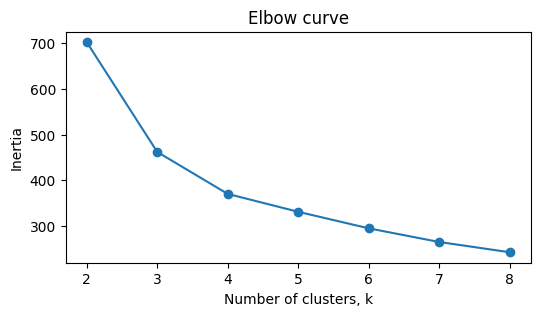

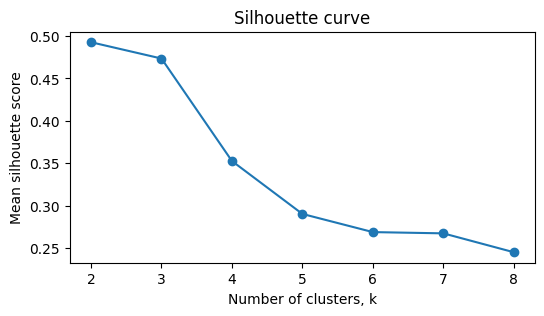

In [6]:

k_values = np.arange(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=int(k), n_init=30, random_state=0).fit(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_))

print("Best silhouette k:", int(k_values[np.argmax(silhouettes)]))
print("Silhouette scores:", dict(zip(k_values.tolist(), np.round(silhouettes, 3).tolist())))

plt.figure(figsize=(6, 3))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters, k")
plt.ylabel("Inertia")
plt.title("Elbow curve")
plt.show()

plt.figure(figsize=(6, 3))
plt.plot(k_values, silhouettes, marker="o")
plt.xlabel("Number of clusters, k")
plt.ylabel("Mean silhouette score")
plt.title("Silhouette curve")
plt.show()



### What to notice

- Inertia must decrease as $k$ increases, so the smallest inertia does not choose $k$.
- Silhouette score can prefer a mathematically clean partition that is not the most useful scientific interpretation.
- In unsupervised work, $k$ is often a modeling decision supported by diagnostics and domain constraints rather than “discovered” by one number.

**Try:** rerun the sweep after removing one telemetry feature or changing the random seed used to generate the data.



# 4. Break K-means on purpose

No clustering algorithm wins on every geometry. The synthetic datasets below include labels only so we can diagnose algorithm behavior with adjusted Rand index (ARI). Real unsupervised data usually does not give you this luxury.


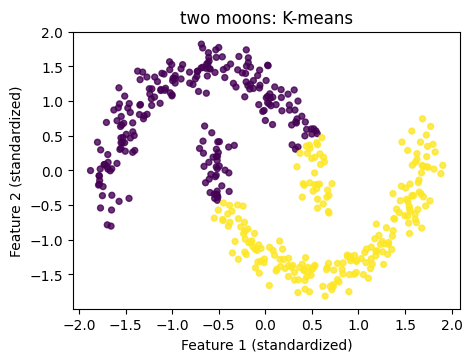

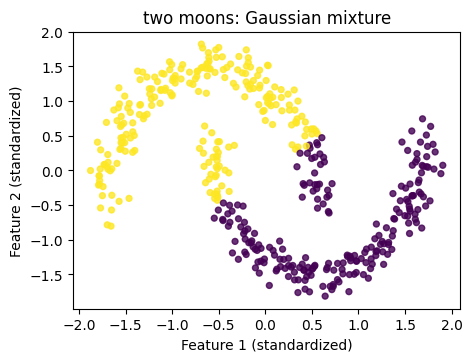

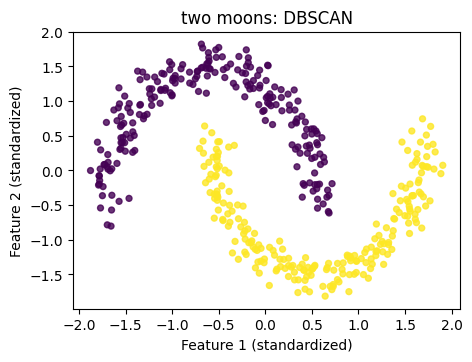

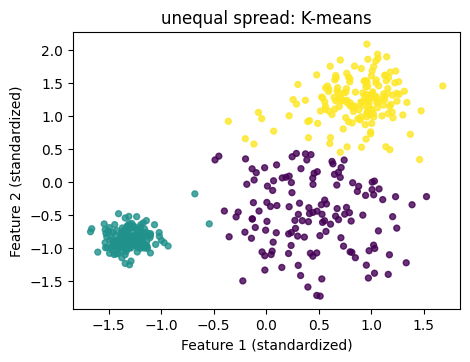

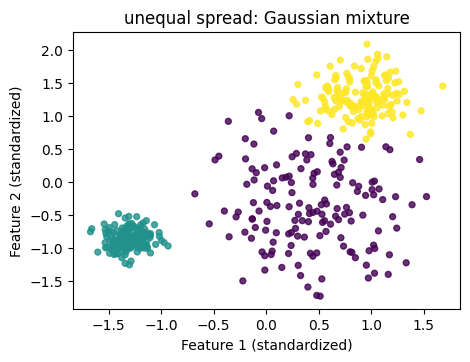

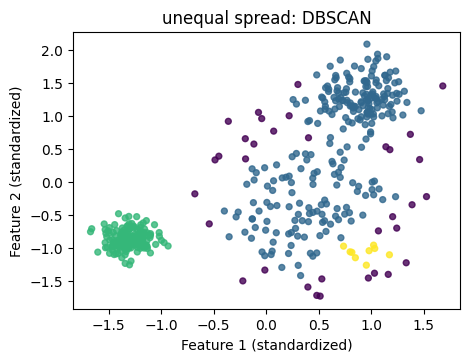

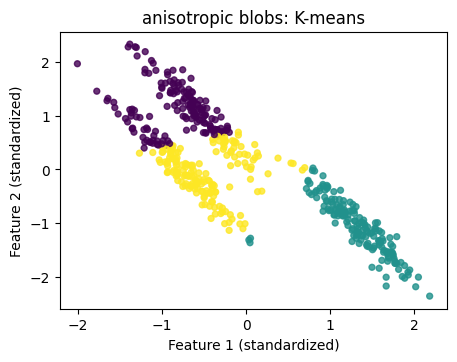

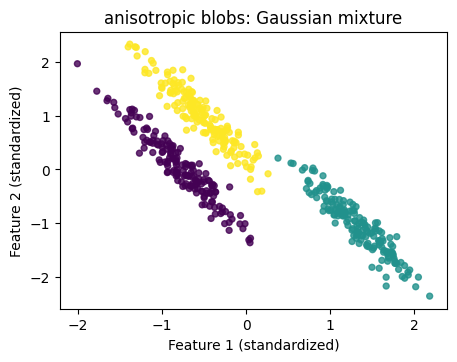

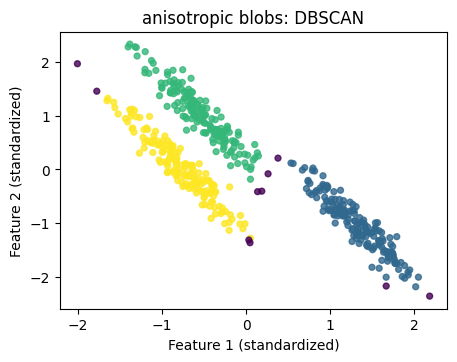

Adjusted Rand index against synthetic ground truth:

two moons
  K-means            0.467
  Gaussian mixture   0.473
  DBSCAN             1.000

unequal spread
  K-means            0.892
  Gaussian mixture   0.929
  DBSCAN             0.549

anisotropic blobs
  K-means            0.572
  Gaussian mixture   1.000
  DBSCAN             0.970


In [7]:

moons_X, moons_y = make_moons(n_samples=450, noise=0.08, random_state=3)

varied_X, varied_y = make_blobs(
    n_samples=450,
    centers=[[-2, -1], [1.7, 0], [3, 3]],
    cluster_std=[0.30, 1.15, 0.55],
    random_state=5,
)

aniso_X, aniso_y = make_blobs(n_samples=500, random_state=170)
transformation = np.array([[0.60834549, -0.63667341], [-0.40887718, 0.85253229]])
aniso_X = aniso_X @ transformation

DATASETS = {
    "two moons": (moons_X, moons_y, 2, 0.28),
    "unequal spread": (varied_X, varied_y, 3, 0.22),
    "anisotropic blobs": (aniso_X, aniso_y, 3, 0.22),
}

results = {}
for name, (data, truth, k, eps) in DATASETS.items():
    data_scaled = StandardScaler().fit_transform(data)
    predictions = {
        "K-means": KMeans(n_clusters=k, n_init=30, random_state=0).fit_predict(data_scaled),
        "Gaussian mixture": GaussianMixture(
            n_components=k, covariance_type="full", n_init=5, random_state=0
        ).fit_predict(data_scaled),
        "DBSCAN": DBSCAN(eps=eps, min_samples=6).fit_predict(data_scaled),
    }
    results[name] = {model: adjusted_rand_score(truth, pred) for model, pred in predictions.items()}

    for model_name, pred in predictions.items():
        plt.figure(figsize=(5, 3.6))
        plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=pred, s=18, alpha=0.8)
        plt.xlabel("Feature 1 (standardized)")
        plt.ylabel("Feature 2 (standardized)")
        plt.title(f"{name}: {model_name}")
        plt.show()

print("Adjusted Rand index against synthetic ground truth:")
for name, scores in results.items():
    print()
    print(name)
    for model_name, score in scores.items():
        print(f"  {model_name:18s} {score:.3f}")



### What to notice

- K-means prefers compact Voronoi regions around centroids.
- A Gaussian mixture can represent elliptical covariance and soft membership, but still assumes a mixture of Gaussian components.
- DBSCAN can recover non-convex shapes and label noise, but its result can be highly sensitive to `eps` and density variation.

**Try:** change only `eps` for DBSCAN. Watch a clean-looking result collapse into one giant cluster or fragment into noise. Parameters are assumptions with better branding.



# 5. Turn the soft-membership temperature dial

We convert negative squared distances into probabilities with a softmax. Temperature controls how sharp the probabilities are.

$$
r_{ik} = \frac{\exp(-d_{ik}^2/T)}{\sum_j \exp(-d_{ij}^2/T)}
$$

**Predict first:** Which temperatures will make almost every point look certain?


T= 0.2: median=1.000, fraction below 0.70=0.000
T= 1.0: median=1.000, fraction below 0.70=0.033
T= 3.0: median=0.957, fraction below 0.70=0.108
T=10.0: median=0.644, fraction below 0.70=0.708


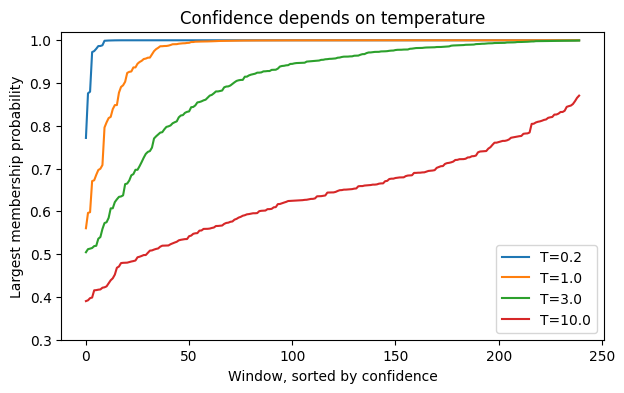

In [8]:

def distance_soft_memberships(X, centers, temperature):
    d2 = np.sum((X[:, None, :] - centers[None, :, :]) ** 2, axis=2)
    scores = -d2 / temperature
    scores -= scores.max(axis=1, keepdims=True)
    weights = np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)

base_model = KMeans(n_clusters=3, n_init=30, random_state=0).fit(X)
temperatures = [0.20, 1.0, 3.0, 10.0]

plt.figure(figsize=(7, 4))
for temperature in temperatures:
    R = distance_soft_memberships(X, base_model.cluster_centers_, temperature)
    confidence = np.sort(R.max(axis=1))
    print(
        f"T={temperature:>4}: median={np.median(confidence):.3f}, "
        f"fraction below 0.70={np.mean(confidence < 0.70):.3f}"
    )
    plt.plot(confidence, label=f"T={temperature}")

plt.xlabel("Window, sorted by confidence")
plt.ylabel("Largest membership probability")
plt.ylim(0.30, 1.02)
plt.title("Confidence depends on temperature")
plt.legend()
plt.show()



### What to notice

The ranking of ambiguous points may be informative, but the absolute probability values are calibrated only under a justified probabilistic model. A distance-softmax score is useful; it is not automatically a true posterior probability.

**Try:** locate the ten least-confident windows at two temperatures. Does the set change, or only the reported certainty?



# 6. PCA as a compressor

PCA keeps directions of maximum variance. Its reconstruction using the first $m$ components is

$$
\hat{X}_m = Z_m V_m + \mu.
$$

**Predict first:** How many components are needed before reconstruction error becomes small?


Explained variance ratios: [0.6301 0.2902 0.0664 0.0067 0.0041 0.0025]
Cumulative explained variance: [0.6301 0.9203 0.9867 0.9934 0.9975 1.    ]


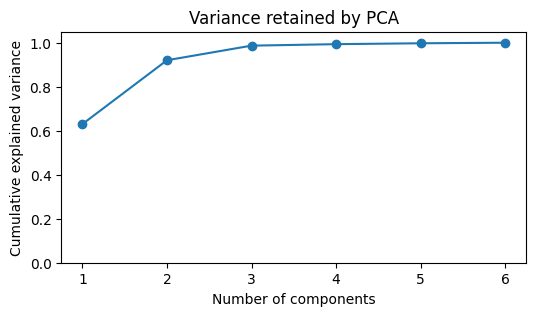

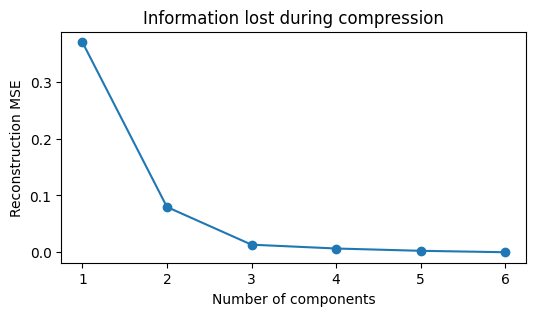

PC 1 strongest absolute loadings: [(np.str_('magnetic_noise'), 0.508), (np.str_('bus_power_w'), -0.507), (np.str_('radio_activity'), -0.469)]
PC 2 strongest absolute loadings: [(np.str_('attitude_error_deg'), 0.702), (np.str_('wheel_vibration_g'), 0.631), (np.str_('thermal_gradient_c'), 0.27)]


In [9]:

full_pca = PCA(n_components=X.shape[1]).fit(X)
cumulative_variance = np.cumsum(full_pca.explained_variance_ratio_)
reconstruction_mse = []

for n_components in range(1, X.shape[1] + 1):
    model = PCA(n_components=n_components).fit(X)
    Z = model.transform(X)
    X_hat = model.inverse_transform(Z)
    reconstruction_mse.append(np.mean((X - X_hat) ** 2))

print("Explained variance ratios:", full_pca.explained_variance_ratio_)
print("Cumulative explained variance:", cumulative_variance)

plt.figure(figsize=(6, 3))
plt.plot(range(1, X.shape[1] + 1), cumulative_variance, marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.ylim(0, 1.05)
plt.title("Variance retained by PCA")
plt.show()

plt.figure(figsize=(6, 3))
plt.plot(range(1, X.shape[1] + 1), reconstruction_mse, marker="o")
plt.xlabel("Number of components")
plt.ylabel("Reconstruction MSE")
plt.title("Information lost during compression")
plt.show()

for component_id, loading in enumerate(full_pca.components_[:2]):
    strongest = np.argsort(np.abs(loading))[::-1][:3]
    print(
        f"PC {component_id + 1} strongest absolute loadings:",
        [(FEATURE_NAMES[i], round(float(loading[i]), 3)) for i in strongest],
    )



### What to notice

- PCA optimizes variance and squared reconstruction error, not cluster separation or scientific interpretability.
- Component signs are arbitrary: multiplying a principal direction and its scores by $-1$ describes the same subspace.
- Scaling before PCA changes what “large variance” means.

**Try:** fit PCA directly to `X_raw`. Which channels dominate the first component, and why?



# 7. NMF as additive latent programs

NMF approximates a nonnegative matrix with two nonnegative factors:

$$
X \approx WH, \qquad W \ge 0, \; H \ge 0.
$$

For telemetry, rows of $H$ can be viewed as additive feature programs, while rows of $W$ describe how strongly each time window uses those programs.


NMF reconstruction MSE: 0.013041356390831796
Program 0: [(np.str_('radio_activity'), 6.118), (np.str_('bus_power_w'), 5.713), (np.str_('wheel_vibration_g'), 1.915)]
Program 1: [(np.str_('wheel_vibration_g'), 2.955), (np.str_('attitude_error_deg'), 2.356), (np.str_('thermal_gradient_c'), 1.25)]
Program 2: [(np.str_('magnetic_noise'), 2.122), (np.str_('thermal_gradient_c'), 1.98), (np.str_('attitude_error_deg'), 0.638)]


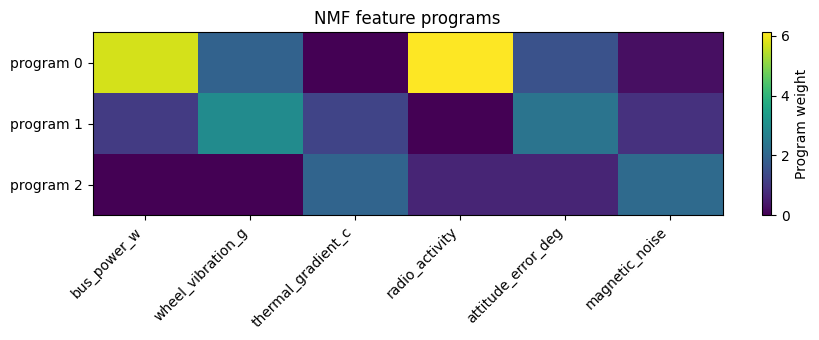

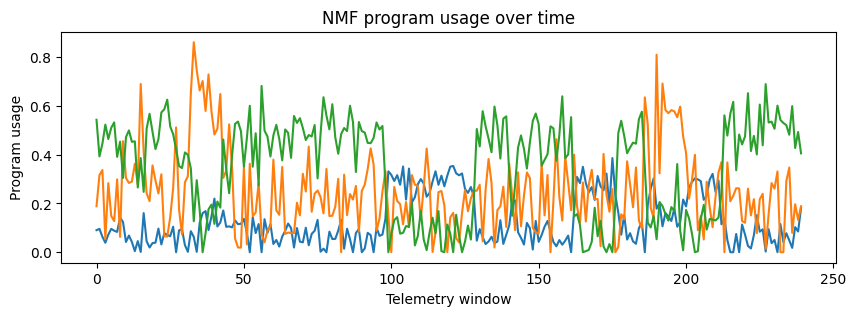

In [10]:

X_nonnegative = X_raw - X_raw.min(axis=0, keepdims=True) + 1e-3
X_nonnegative = X_nonnegative / X_nonnegative.mean(axis=0, keepdims=True)

nmf = NMF(n_components=3, init="nndsvda", max_iter=2000, random_state=0)
W = nmf.fit_transform(X_nonnegative)
H = nmf.components_
X_hat = W @ H

print("NMF reconstruction MSE:", np.mean((X_nonnegative - X_hat) ** 2))
for program_id, program in enumerate(H):
    top = np.argsort(program)[::-1][:3]
    print(
        f"Program {program_id}:",
        [(FEATURE_NAMES[i], round(float(program[i]), 3)) for i in top],
    )

plt.figure(figsize=(9, 3.5))
plt.imshow(H, aspect="auto")
plt.xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=45, ha="right")
plt.yticks(range(H.shape[0]), [f"program {i}" for i in range(H.shape[0])])
plt.colorbar(label="Program weight")
plt.title("NMF feature programs")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(W)
plt.xlabel("Telemetry window")
plt.ylabel("Program usage")
plt.title("NMF program usage over time")
plt.show()



### What to notice

- Nonnegativity encourages additive explanations, but a component is not automatically a real physical subsystem.
- NMF is not unique: component order, scale, initialization, and rank can all change the factorization.
- Interpretation requires stability checks and external evidence, just like clustering.

**Try:** fit ranks 2 through 6. Track reconstruction error and whether the same feature programs recur.



# 8. Viterbi smoothing: time as evidence

K-means treats windows independently. An HMM-style decoder combines per-window evidence with a transition matrix.

A high self-transition probability says: **spacecraft modes usually persist**.


stay=0.55: switches=17
stay=0.75: switches=15
stay=0.92: switches=11


stay=0.99: switches=10


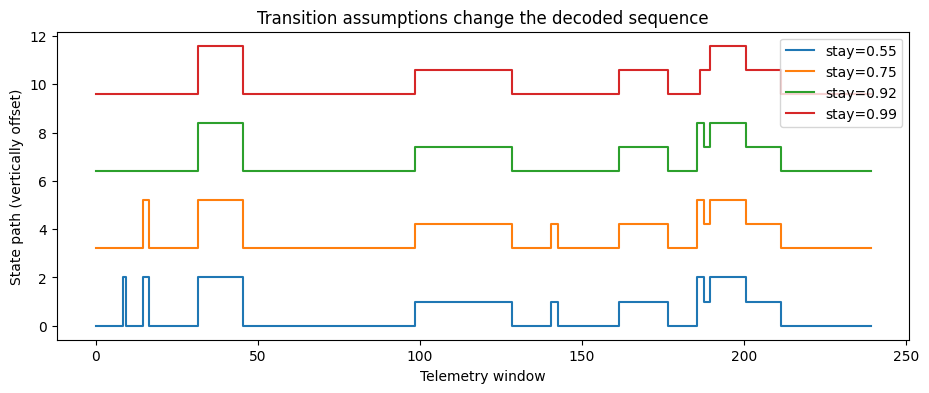

In [11]:

def viterbi_decode(log_emissions, transition, start_probability):
    log_emissions = np.asarray(log_emissions, dtype=float)
    transition = np.asarray(transition, dtype=float)
    start_probability = np.asarray(start_probability, dtype=float)

    n_steps, n_states = log_emissions.shape
    score = np.empty((n_steps, n_states))
    backpointer = np.zeros((n_steps, n_states), dtype=int)
    score[0] = np.log(start_probability) + log_emissions[0]

    log_transition = np.log(transition)
    for t in range(1, n_steps):
        candidates = score[t - 1][:, None] + log_transition
        backpointer[t] = np.argmax(candidates, axis=0)
        score[t] = candidates[backpointer[t], np.arange(n_states)] + log_emissions[t]

    path = np.empty(n_steps, dtype=int)
    path[-1] = np.argmax(score[-1])
    for t in range(n_steps - 2, -1, -1):
        path[t] = backpointer[t + 1, path[t + 1]]
    return path

R = distance_soft_memberships(X, base_model.cluster_centers_, temperature=3.0)
start = np.full(3, 1 / 3)

paths = {}
for stay_probability in [0.55, 0.75, 0.92, 0.99]:
    transition = np.full((3, 3), (1 - stay_probability) / 2)
    np.fill_diagonal(transition, stay_probability)
    path = viterbi_decode(np.log(R + 1e-12), transition, start)
    paths[stay_probability] = path
    print(
        f"stay={stay_probability:.2f}: switches={np.count_nonzero(np.diff(path))}"
    )

plt.figure(figsize=(11, 4))
for offset, (stay_probability, path) in enumerate(paths.items()):
    plt.step(
        np.arange(len(path)),
        path + 3.2 * offset,
        where="mid",
        label=f"stay={stay_probability:.2f}",
    )
plt.xlabel("Telemetry window")
plt.ylabel("State path (vertically offset)")
plt.title("Transition assumptions change the decoded sequence")
plt.legend()
plt.show()



### What to notice

- Temporal smoothing can remove implausible one-window flicker.
- Too much stickiness can erase real short events.
- The transition matrix contributes evidence; it is not a cosmetic postprocessing setting.

**Try:** create a transition matrix in which one state is easy to enter but hard to leave. Predict the resulting asymmetry before running it.



# 9. Autoencoders: the nonlinear next step

PCA uses a linear encoder and decoder. An autoencoder learns nonlinear functions:

$$
z = f_\theta(x), \qquad \hat{x} = g_\phi(z),
$$

by minimizing reconstruction loss such as

$$
\sum_i \left\|x_i - g_\phi(f_\theta(x_i))\right\|_2^2.
$$

A small telemetry autoencoder might use the shape

```text
6 inputs → 3 hidden units → 2-dimensional code → 3 hidden units → 6 reconstructed outputs
```

### Design challenge

Before opening a framework tutorial, answer these:

1. Why must the bottleneck or another constraint prevent the network from learning a trivial identity map?
2. Why can low reconstruction error coexist with a useless representation?
3. How would you compare the autoencoder's two-dimensional code with PCA's two-dimensional projection?
4. How could reconstruction error become an anomaly score, and what could go wrong?

Then run the official TensorFlow tutorial:  
https://www.tensorflow.org/tutorials/generative/autoencoder



# 10. Tutorial library

## Fast refreshers

- **NumPy broadcasting:** https://numpy.org/doc/stable/user/basics.broadcasting.html
- **NumPy SVD:** https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html
- **NumPy beginner fundamentals:** https://numpy.org/doc/stable/user/absolute_beginners.html

## Structured clustering tutorials

- **Google clustering course:** https://developers.google.com/machine-learning/clustering
- **K-means overview:** https://developers.google.com/machine-learning/clustering/kmeans/overview
- **Clustering workflow:** https://developers.google.com/machine-learning/clustering/workflow
- **K-means strengths and failure modes:** https://developers.google.com/machine-learning/clustering/kmeans/advantages-disadvantages

## Visual examples you can run

- **K-means assumptions:** https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html
- **Clustering algorithm comparison:** https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html
- **Silhouette analysis:** https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
- **PCA on Iris:** https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html
- **Faces with PCA, NMF, ICA, and sparse methods:** https://scikit-learn.org/stable/auto_examples/decomposition/plot_faces_decomposition.html

## Math-forward and research routes

- **Gaussian mixtures and EM:** https://scikit-learn.org/stable/modules/mixture.html
- **Stanford CS229 materials:** https://cs229.stanford.edu/materials.html
- **HMM tutorial:** https://hmmlearn.readthedocs.io/en/stable/tutorial.html
- **K-means++ paper:** https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf
- **Original NMF paper:** https://www.nature.com/articles/44565
- **Autoencoder tutorial:** https://www.tensorflow.org/tutorials/generative/autoencoder



# Mini-project menu

1. **Reliability dashboard:** summarize restart stability, silhouette, confidence, and cluster sizes in one report.
2. **Anomaly detector:** rank windows by centroid distance or reconstruction error, then inspect false alarms.
3. **K-means versus GMM:** compare hard labels, soft membership, covariance assumptions, and uncertain regions.
4. **PCA versus NMF:** compare reconstruction and interpretability across ranks.
5. **Temporal segmentation:** tune transition matrices and quantify the tradeoff between flicker and oversmoothing.
6. **Unsupervised model card:** document similarity, preprocessing, initialization, model assumptions, validation evidence, intended use, and failure modes.

## Final reflection

Pick one result from this notebook and write three sentences:

1. **What structure did the model find?**
2. **Which assumption made that structure visible?**
3. **What external evidence would be needed before attaching a real-world meaning?**

That third sentence is the difference between discovering a pattern and inventing a story.
